In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import joblib
sys.path.append('../src')

In [3]:
contour = 'mlspace'
RQUID = 'INSERT_YOUR_CLIENT_ID_HERE'
AUTH_DATA = 'INSERT_YOUR_CLIENT_SECRET_HERE'
mlspace_auth = {'OAUTH_URL': 'https://ngw.devices.sberbank.ru:9443/api/v2/oauth',
                'API_URL': 'https://gigachat.devices.sberbank.ru/api/v1',
                'TOKEN': None}
sigma_auth = {'OAUTH_URL': 'https://sm-auth-sd.prom-88-89-apps.ocp-geo.ocp.sigma.sbrf.ru/api/v2/oauth',
              'API_URL': 'https://gigachat.devices.sberbank.ru/api/v1',
              'TOKEN': None}
total_auth = {'mlspace': mlspace_auth,
              'sigma': sigma_auth}

## Чтение данных

In [4]:
data_la = joblib.load('data/data_longanswer.pkl')

## Создание Sampler'а и Scorer'а

In [5]:
from llm_val.sampler.LongAnswerSampler import LongAnswerSampler

sampler_la = LongAnswerSampler(data_la)

/home/user/conda/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
from llm_val.utils.metrics import METRICS
from llm_val.scorer.UniversalScorer import UniversalScorer

In [7]:
scorer = UniversalScorer(metrics=METRICS)

## Создание модели

In [8]:
from llm_val.model.MultiThreadGigaModel import MultiThreadGigaModel

In [9]:
model = MultiThreadGigaModel(n_jobs=8,
                             rquid=RQUID,
                             auth_data=AUTH_DATA,
                             oauth_url=total_auth[contour]['OAUTH_URL'],
                             api_url=total_auth[contour]['API_URL'],
                             token=total_auth[contour]['TOKEN'])

## Validation

Validation - это сущность, главной целью которой является проведение тестов, агрегация и сохранение результатов. Для информативного отображения результатов тестов, а также агрегации результатов по блокам, `Validation` тянет конфиги из `src/llm_val/configs`, в которых указана вся необходимая информация по всем тестам. 

На текущий момент Validation умеет проводить тесты и сохранять их результаты либо в .pkl, либо в .xlsx.

`Validation` сохраняет результаты тестов в директорию `save_dir`. Несколько важных моментов про работу этого сохранения:
1. Если директории `save_dir` нет, то объект класса `Validation` создаст её;
2. Внутри директории `save_dir` при каждом запуске создается директория со временем запуска метода `validate()`. Внутри этой директории будут лежать результаты запуска тестов;
3. Помимо того, что результаты сохраняются в директорию запуска тестов с соответствующим временем, результаты последнего запуска `validate()` сохраняются в корень `save_dir`.

Итоговая иерархия директории `save_dir` будет выглядеть следующим образом:
``` Linux
test_results
|---2024_12_16_15_21_19
|   |---test_results.xlsx
|   |---test_results.pkl
|   |---precomputed.pkl
|---2024_12_16_15_18_55
|   |---test_results.xlsx
|   |---test_results.pkl
|   |---precomputed.pkl
|---2024_12_16_15_18_26
|   |---test_results.xlsx
|   |---test_results.pkl
|   |---precomputed.pkl
|---test_results.xlsx
|---test_results.pkl
|---precomputed.pkl

```

In [10]:
from llm_val.validation import Validation

Для проведения тестов необходимо создать словарь, в котором описаны параметры тестов. Будут проведены только те тесты, которые указаны в данном словаре. Если теста в словаре с параметрами нет в конфигах с описанием тестов(по умолчанию находящихся в `src/llm_val/configs`), то на этапе создания `Validation` будет выведен warning и тест проводиться не будет.

In [11]:
param_config = {'valtest_complex_data_quality': {'data_types': ('test', 'test')}, 
                'valtest_annotation_quality': {'data_type': 'test'}, 
                'valtest_train_test_independence': {'model': model,
                                                    'test_data_type': 'test',
                                                    'train_split_data_type': 'test',
                                                    'is_mask_option': False,
                                                    'is_mask_word': True,
                                                    'is_split_gini_quantile': True,
                                                    'mask_word_iterations': 5,
                                                    'mask_word_semaphore_threshold': (0.5, 0.7)},
                'hello_test': {'hi': 'good'}}

In [12]:
validor = Validation(sampler=sampler_la,
                     scorer=scorer,
                     param_config=param_config,
                     desc_config='../src/llm_val/configs/test_desc.json',
                     agg_config='../src/llm_val/configs/test_agg.json',
                     save_dir='./test_results',
                     precomputed=None, 
                     is_semaphore_desc_info=True)

/home/jovyan/llm_val_agg/examples/../src/llm_val/validation.py:174: UserWarning: Тесты hello_test не будут проведены, так как их нет в конфиге допустимых тестов
  warnings.warn(warn_msg, category=UserWarning)


Для запуска всех тестов необходимо вызвать метод `validate()`. Помимо сохранения результатов по пути `save_dir` из параметров `Validation`, он возвращает кортеж с двумя словарями: в одном лежат результаты каждого теста, а в другом - агрегация по каждому блоку.

Run test valtest_complex_data_quality...
Run test valtest_annotation_quality...
Run test valtest_train_test_independence...


100%|██████████| 200/200 [01:28<00:00,  2.25it/s]


Hello  0.38


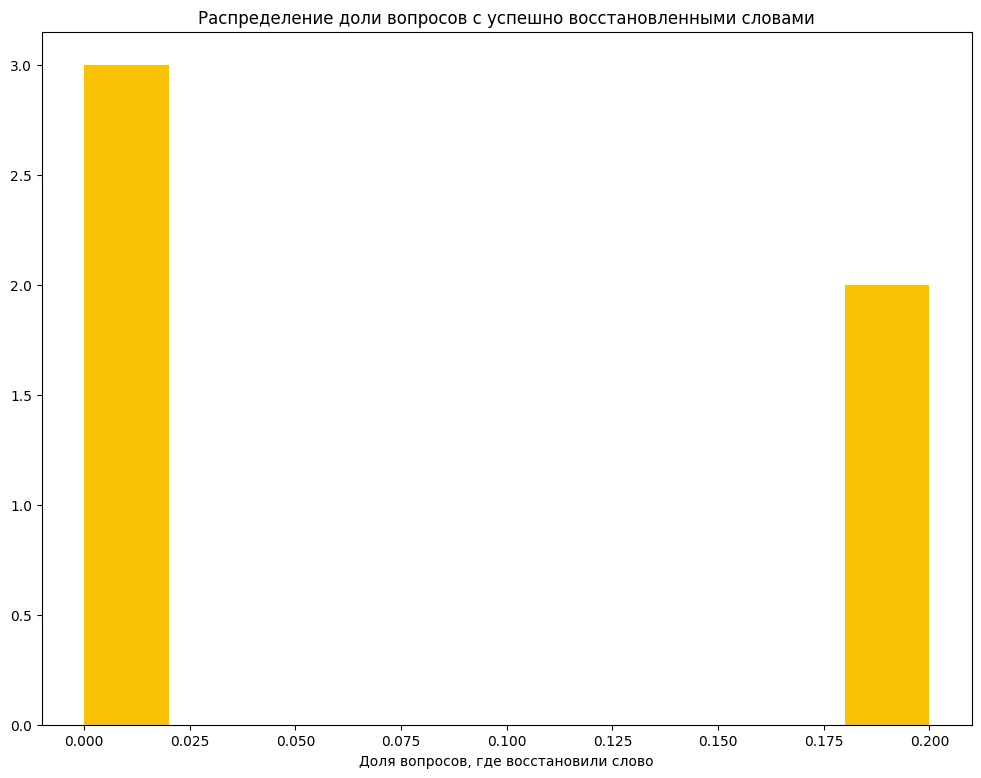

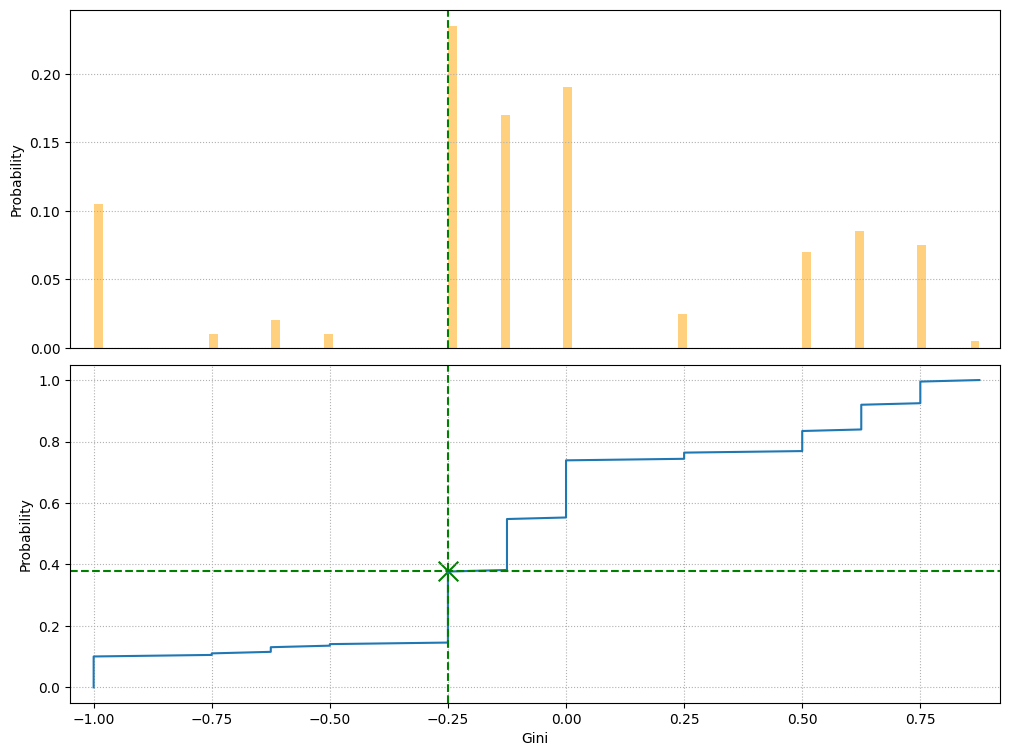

In [13]:
table, agg = validor.validate(save_res_pkl=True,
                              save_excel=True)

In [14]:
agg

{'Качество данных': {'Светофор по блоку': 'red',
  'Количество проведенных тестов': 3}}

In [15]:
table

{'valtest_complex_data_quality': {'semaphore': 'red',
  'result_plots': [],
  'result_dataframes': [            Проверка  test Результат теста
   0    Доля дубликатов   0.0           green
   1  Доля противоречий   0.0           green
   2   Доля пересечений   1.0             red]},
 'valtest_annotation_quality': {'semaphore': 'yellow',
  'result_plots': [],
  'result_dataframes': [           Наименование критерия  Значение Результат теста
   0      Альфа-версия Криппендорфа  0.097620          yellow
   1  Попарный коэффициент Спирмена  0.222222          yellow]},
 'valtest_train_test_independence': {'semaphore': 'green',
  'result_plots': [<Figure size 1200x900 with 1 Axes>,
   <Figure size 1200x900 with 2 Axes>],
  'result_dataframes': [                                            Проверка  Статистика  \
   0  Доля восстановленных маскированных слов в текс...        0.08   
   1      Квантиль Gini модели, разделяющей test и test        0.38   
   
     Светофор по проверке  
   0     

In [16]:
table['valtest_train_test_independence']['result_dataframes'][0]

,Проверка,Статистика,Светофор по проверке
0,Доля восстановленных маскированных слов в текс...,0.08,green
1,"Квантиль Gini модели, разделяющей test и test",0.38,green
